# October 12 full day — without dev-sell-all

**October 12, 2026, 00:00–24:00 UTC · 10,000 SOL starting wallet.**
This notebook reviews the completed native fork run with the developer-sell-all entry rule disabled.
Original sizing, the first-two-slot search window, +5% own take profit, five-minute timeout,
5% slippage, creator-fee accounting and one-slot execution delay stay unchanged.

**251 profitable · 318 losing · 80 unresolved · 238 submitted failed entries.**
Realized net is **−109.602394368 SOL**, including failed-entry fees. Another
**152.319150420 SOL** remains committed to unresolved positions. These positions
are not counted as realized losses, and final portfolio PnL remains unknown.

The notebook reads frozen local artifacts. **Run All does not rerun the backtest,
query ClickHouse/RPC, place orders, or change production.** Use the registered
**Python 3.13.12 (Sniper research)** kernel.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import plotly.io as pio
from IPython.display import display, Markdown

ROOT = next((p if (p/'src/backtest').is_dir() else p/'onchain-backtest-engine')
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'src/backtest').is_dir() or (p/'onchain-backtest-engine/src/backtest').is_dir())
sys.path.insert(0, str(ROOT/'notebooks'))
from sniper_oct12_day_review import FullDayReview, GROUPS
DATA = ROOT/'var/dnipro/sniper-oct12-no-dev-flat-review-20261016-v1'
if not (DATA/'context-receipt.json').exists():
    DATA = Path('/Volumes/KINGSTON/solana-research/sniper-oct12-no-dev-flat-review-20261016-v1')
pio.renderers.default = 'plotly_mimetype'
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 100)
review = FullDayReview(DATA)
display(review.summary_table())

,date_utc,wallet_sol,dev_sell_all_required,signals,filled,profitable,losing,unresolved,failed_entries,risk_rejections,realized_net_pnl_sol,open_committed_cost_sol,final_portfolio_pnl,detailed_log_tokens
0,2026-10-12 00:00–24:00,10000,False,887,649,251,318,80,238,0,-109.602394368,152.319150420,Unknown — 80 unresolved,78


## Realized PnL, cash and committed cost

The first panel recognizes closed-position results at the simulated sell boundary
and charges failed-entry fees when released. Open exposure is excluded.
The second panel shows cash change, not portfolio PnL. The third shows committed
cost, including failed exit fees. All three curves reconcile to the native ledger.
The horizontal axis uses slots; hover shows exact UTC and transaction boundaries.

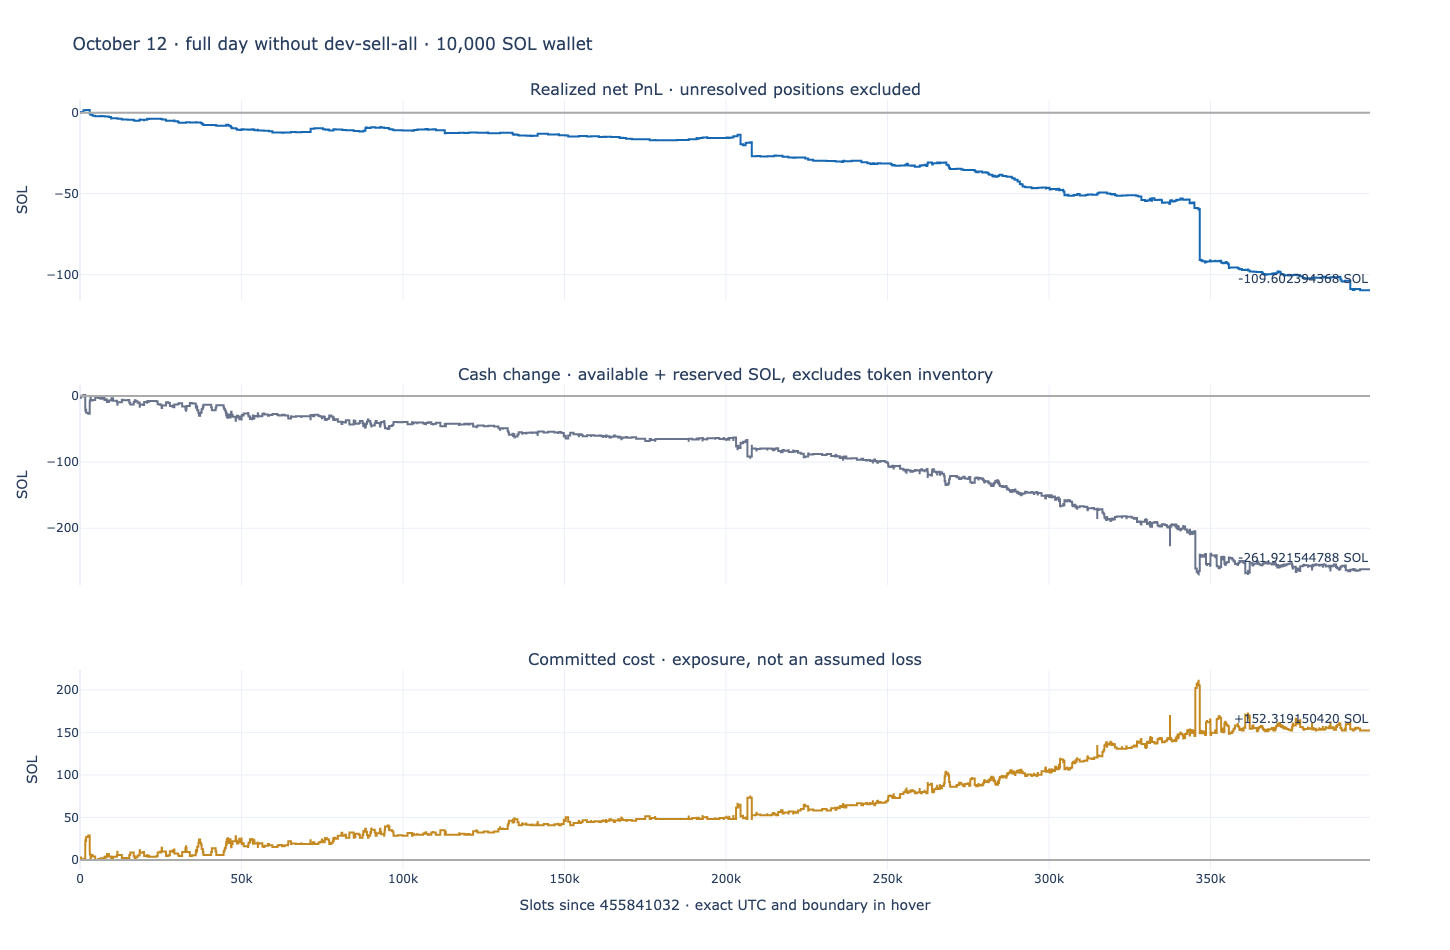

In [2]:
display(review.strategy_figure())

## Complete position lists

Every signal appears exactly once below. A submitted failed entry has no buy fill
and pays its execution fee; a risk rejection would pay no fees. There were zero
risk rejections. Unresolved exposure is kept separate from losing positions.
Token, developer and tracked-buyer links use GMGN.

In [3]:
for group in GROUPS:
    count = int((review.table.group == group).sum())
    if count:
        display(Markdown(f'### {group} — {count} tokens'))
        review.display_table(group)

### Profitable — 251 tokens

token,group,entry_slot,exit_slot,entry_sol,closed_pnl_sol,open_committed_cost_sol,failed_execution_fees_sol,first_causal_blocker,gmgn_url
MIBI,Profitable,455841258,455841342,2.828017490,0.433451085,0.000000000,0.000000000,,https://gmgn.ai/sol/token/A2vTTZyjaTn2Ly3FTnUqi34rsDptNzA968owwFbrpump
Nuts,Profitable,455842073,455842077,1.328059060,0.767069205,0.000000000,0.000105000,,https://gmgn.ai/sol/token/BYgPwdCQ4xEQrRuEud2uFU2AYPCdYGoNbu6yJr2hpump
Jeremiah,Profitable,455842136,455842137,1.422415220,0.318340930,0.000000000,0.000000000,,https://gmgn.ai/sol/token/DraQMm86aowauGjQ1HTcZUkuh7JQfn89qyn3sdgTpump
S&P500,Profitable,455842767,455842770,1.782178949,0.100335405,0.000000000,0.000000000,,https://gmgn.ai/sol/token/4A6FnkFxfLUA7rGwVkYKXyenXsn7Zhbw8NuXVqU8pump
VMO,Profitable,455847351,455847352,0.740063180,0.076158584,0.000000000,0.000000000,,https://gmgn.ai/sol/token/2JJNpAczhb6tfus32C91eNPf1S6FBEDVaDfxdmvHpump
‎,Profitable,455849380,455850768,2.423446245,0.076200041,0.000000000,0.000000000,,https://gmgn.ai/sol/token/7dEbQAAh3S2R35T8ogFmQv52eE5G6Dur8hQWqJKNpump
LACY,Profitable,455859442,455859447,1.558277166,0.525046933,0.000000000,0.000000000,,https://gmgn.ai/sol/token/B6qvFCbGuvha1UPcauooG4Ba8p7Aj4abtjduX8SHpump
Bino,Profitable,455859521,455859527,1.766727557,0.273882110,0.000000000,0.000000000,,https://gmgn.ai/sol/token/98aZvbY1X7ZSDUds7Kgb2eUqXjbtCGGowbqjK6UWpump
PENUS,Profitable,455860896,455860898,4.733892769,0.366954446,0.000000000,0.000000000,,https://gmgn.ai/sol/token/364BmcVsmFMEM2nWqLY2wcFzayWcxTVZ4JQ9Rm97pump
Diggs,Profitable,455861832,455861836,1.274801920,0.575241764,0.000000000,0.000000000,,https://gmgn.ai/sol/token/613F4Vp5eDxxHUjuqF3scowYdro8fjTyZe48v4FApump


### Losing — 318 tokens

token,group,entry_slot,exit_slot,entry_sol,closed_pnl_sol,open_committed_cost_sol,failed_execution_fees_sol,first_causal_blocker,gmgn_url
ENTH,Losing,455842659,455844037,18.243462859,-2.170983484,0.000000000,0.000000000,,https://gmgn.ai/sol/token/3Ztm75oVzHKkXsCNx8UmFnKkhMThf7yBpY9oTspKLKbv
VAKAFU,Losing,455842692,455844071,4.128785331,-0.188560373,0.000000000,0.000000000,,https://gmgn.ai/sol/token/CzVTWQgbjBMQhGrUsAz15hX8qdpFxTWTGeatbR5Bpump
RAYLS,Losing,455842932,455844304,4.673902373,-0.564938177,0.000000000,0.000000000,,https://gmgn.ai/sol/token/78nYgkFzj4uaAgEkkcMjYj8P91k2Wyj2ou5miWBBpump
Cases,Losing,455843562,455844936,1.674826280,-0.591664455,0.000000000,0.000000000,,https://gmgn.ai/sol/token/AwaTyYehCQDErcKcznCmAP9VcjsHgwKgMX7tmvGcpump
SELU,Losing,455844364,455845739,4.092158155,-0.312374029,0.000000000,0.000000000,,https://gmgn.ai/sol/token/2tQzVURqQkMEGpHHqdFqHonvG4u3p8wyoGVg7Ls6pump
MINTY,Losing,455846667,455848036,1.085985600,-0.118997972,0.000000000,0.000000000,,https://gmgn.ai/sol/token/6HH1Wow3SUZQ2ugjcBxDdjfy9VKhPExtNtEMsNNzpump
ZAVE,Losing,455847427,455848795,0.955490140,-0.106305519,0.000000000,0.000000000,,https://gmgn.ai/sol/token/GdD2dv1jTLX7E6dqDmAi2uVXRDuhm9gmkVWYhLE5pump
BOOGIE,Losing,455848581,455849955,1.739197000,-0.269039700,0.000000000,0.000000000,,https://gmgn.ai/sol/token/EkX23iEtz3EeB4okuK4M5sFH8s7SmaGjZUVnRebcpump
LUTIME,Losing,455848618,455849994,1.081371080,-0.079296259,0.000000000,0.000000000,,https://gmgn.ai/sol/token/6hanGNNiPTmFiMBHt81uToeRLHL5HK3CmbLmq7Xopump
kidlon,Losing,455849283,455850665,1.736019046,-0.877084978,0.000000000,0.000000000,,https://gmgn.ai/sol/token/GhmC3F4we7x1Lo5tpnnXF1srsh8J5xy2gRy8NzPRpump


### Unresolved — 80 tokens

token,group,entry_slot,exit_slot,entry_sol,closed_pnl_sol,open_committed_cost_sol,failed_execution_fees_sol,first_causal_blocker,gmgn_url
WSB,Unresolved,455852380,<NA>,0.627993300,—,0.627993300,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/DjWRDKNHZy9x8KwHYzCHAeQXrEVW8j71JpiHhKcNpump
DRAUMYR,Unresolved,455852492,<NA>,0.994504960,—,0.994504960,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/46JaiTMEt5eAkomaeBgbe7ftjDeaMww5sHU8BqyHpump
BPAYCAT,Unresolved,455858841,<NA>,2.212021888,—,2.212021888,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/FT7JCTxVyUJjH6M7zdp4GhpsJtcPK6UQvhFqUqYBpump
NORMIE,Unresolved,455865713,<NA>,0.833673640,—,0.833673640,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/5TwrtsQn6yNJ8ZUjkfnZ7FarJPyUUX447QRKCUd9pump
,Unresolved,455879068,<NA>,1.201924460,—,1.201924460,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/DHohoH2CjbHQzdVfcPF8zL967ukxUjHkyEFff5vWpump
Kellon,Unresolved,455885870,<NA>,2.500301288,—,2.500301288,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/BhjFppF6NQiNbMvuLvBTrVbvWmV3FkomNzFe7nrQTQrg
PADPAD,Unresolved,455886586,<NA>,0.762071359,—,0.762071359,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/8AevP9LKgNoc72pWLMxNPTKsxKQpb8FCgWnUYu9Apump
Fibonacci,Unresolved,455887236,<NA>,4.548362160,—,4.548362160,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/CFUAHgH6SFQtRcRKyu2JJGoqQnHu1KxFwhekYaoApump
Campfire,Unresolved,455889170,<NA>,1.581176880,—,1.581176880,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/Gchzo2KvAKEbJmCB532SA3y54tdK2HifgoMxh93zpump
FS,Unresolved,455902514,<NA>,0.773910900,—,0.773910900,0.000000000,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,https://gmgn.ai/sol/token/3afDTMsw7R76MMPRqAQo7rtUrSiG22QaKug5Zpmppump


### Entry failed — 238 tokens

token,group,entry_slot,exit_slot,entry_sol,closed_pnl_sol,open_committed_cost_sol,failed_execution_fees_sol,first_causal_blocker,gmgn_url
ARCDOG,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/7bHUu6Lxcy75vuR6EgNuepjwpUUBthDbwVqAode2pump
apelink,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/2ikMciSZ1nK1X9E8X7U5trw3Tc9jW1Ud7FjrhAxPpump
muffincat,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/HPBYBXbKucX3aE4kQ1WucumFGZmEnVLBuevQAbuupump
COMPANY,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/FFnvBUT8ijcLhLML9mfWxQyrLc1ZtA1j8aKGU8bWpump
TARDM,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/7S2aR88192Wf3qyHMhjjw1dvUtMg6wKs6zzJkzoNpump
CHEER,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/5rRCKzDbNiPLv2SJq5DPbSXMGfngFYZVD1yndvb3pump
PF,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/D5DDVQvAkUADg8eiYHmCziY4jdAZRiC8bsEwPPe8pump
veil,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/DgQbPXHkkuiAAHNQGZuYVKo9wfYp8Xnt3dYdywjXpump
SCAN,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/B9BDTYZkYdcCLnZFN22FWRd95mu7kVyjuWP9YwFhpump
qPad,Entry failed,<NA>,<NA>,0.000000000,—,0.000000000,0.000105000,,https://gmgn.ai/sol/token/Geq77hxKaY36st5BA7j593nFTHAoivhFtNJ6s4z2qPad


## Browse any token

Choose an outcome and token, or search a symbol/mint. The browser requires a
running kernel; complete saved examples are below for inspection without one.

Green ▲ and red ▼ are actual simulated buys and sells at average **curve** fill
prices. Hollow diamonds are decisions drawn at a historical reference price;
black crosses are failed attempts, not fills. Curve prices exclude trading fees,
network fees and rent, which remain in the position metadata and ledger.
The dotted green line in the PnL panel is the own +5% take-profit threshold.

Plots preserve transaction order. Tick labels are slots since launch, and hover
keeps the full native boundary as a string. Native block-clock execution points
are simulated landing assumptions, not observed on-chain transactions.

In [4]:
display(review.browser())

## Saved examples

The following cover the biggest closed winner, biggest closed loser, missing
seller-inventory evidence, a fixed-transfer conflict, a failed entry, and a token
with detailed native evaluations. Change `TOKEN` below to inspect any mint from
the tables.

Historical context runs from launch through exit plus 30 seconds. Unresolved
positions retain approximately 6½ minutes after entry; failed entries retain
50 seconds after their signal. Historical reserve discontinuities break the
price line. Continuing historical trading after a blocker is not a proven
continuation of the simulated position.

,Recorded native metadata
status,CLOSED
reason,TARGET
signal_slot,455912387
signal_time,1791778777
entry_slot,455912388
entry_time,1791778777
exit_signal_slot,455912424
exit_slot,455912425
exit_time,1791778785
budget_lamports,4523407920


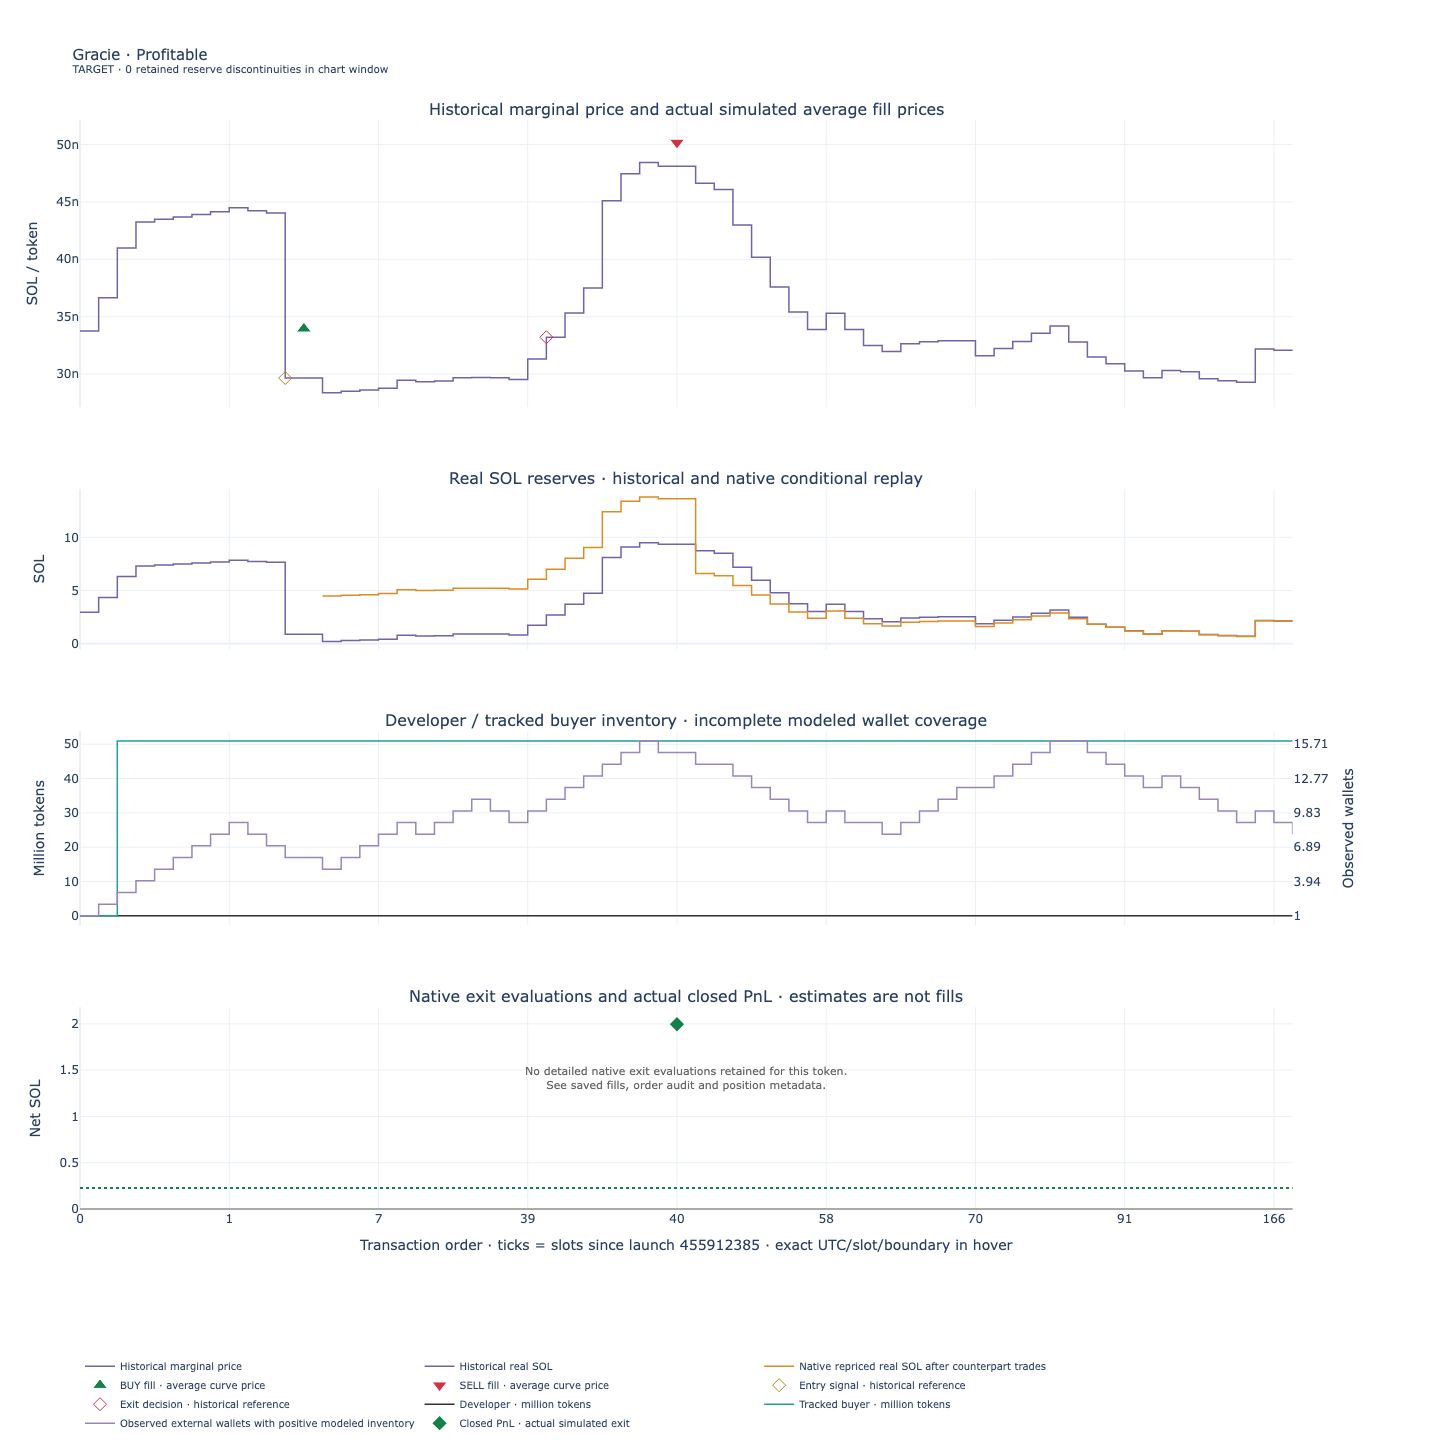

**Complete order audit for this token**

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason
0,1958128792006296409,1958128796301262848,0dbfea8de73a2fbdb8d1e9320d87b0a2cec5ca32c39c8d307fb28d8835bda3f5,50,ORDER_ACCEPTED_AND_RESERVED,,
1,1958128796301262848,,0dbfea8de73a2fbdb8d1e9320d87b0a2cec5ca32c39c8d307fb28d8835bda3f5,60,ORDER_FILLED_ATOMICALLY,1,
2,1958128950920086394,1958128955215052800,fd341808535f4575d4a9e1cdf1f8695ce48acbb98a3d110fb62252b63d9d5d01,50,ORDER_ACCEPTED_AND_RESERVED,,
3,1958128955215052800,,fd341808535f4575d4a9e1cdf1f8695ce48acbb98a3d110fb62252b63d9d5d01,60,ORDER_FILLED_ATOMICALLY,1,


Detailed step logs were not retained for this token. The signal record, fills and order audit above are original saved evidence.

,Recorded native metadata
status,CLOSED
reason,TIMEOUT
signal_slot,456186309
signal_time,1791838674
entry_slot,456186310
entry_time,1791838674
exit_signal_slot,456187678
exit_slot,456187679
exit_time,1791838974
budget_lamports,55290506456


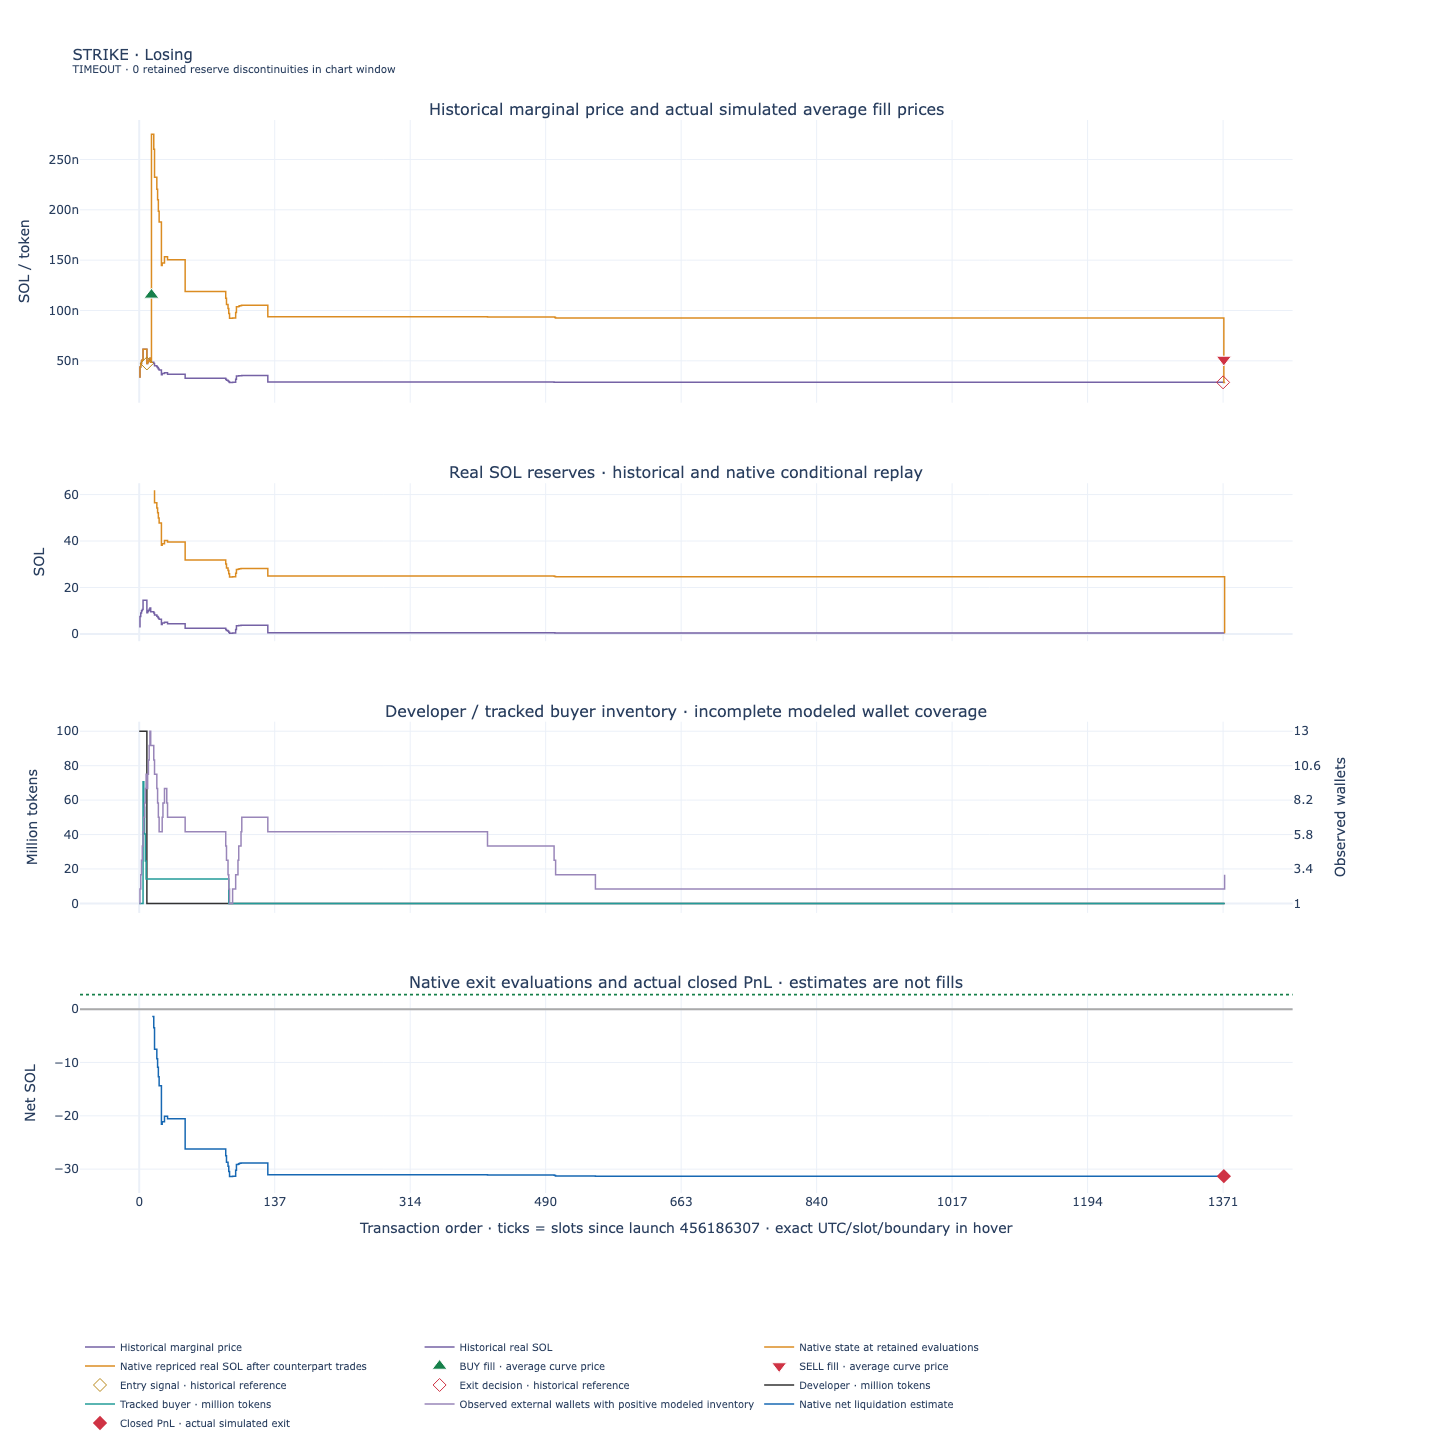

**Complete order audit for this token**

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason
0,1959305278037951072,1959305282332917760,bf9d6d05ccc660662e1b5baf5f74759e4b6d2fc6365e35e738d8f435f54b642c,50,ORDER_ACCEPTED_AND_RESERVED,,
1,1959305282332917760,,bf9d6d05ccc660662e1b5baf5f74759e4b6d2fc6365e35e738d8f435f54b642c,60,ORDER_FILLED_ATOMICALLY,1,
2,1959311157848178688,1959311162143145984,d6b651ae66c8e7d3e0afd1fd7a0eefe84866743531b0d4af506c6aa65d55a06a,50,ORDER_ACCEPTED_AND_RESERVED,,
3,1959311162143145984,,d6b651ae66c8e7d3e0afd1fd7a0eefe84866743531b0d4af506c6aa65d55a06a,60,ORDER_FILLED_ATOMICALLY,1,


**Retained detailed evaluations: first and last rows; full log stays in native/strategy_trace.csv**

,mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,wallet,budget_lamports,real_sol,virtual_sol,virtual_tokens,wallet_tokens,...,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
0,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305278037951072,456186309,1791838674,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,55290506456,,39063014529,824053145739351,14091538976020,...,1000000,93670922139,63670922139,480403277989989,54607907610,456383114090489,,,,,,,,,
1,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305278037951072,456186309,1791838674,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,,39063014529,824053145739351,14091538976020,...,,,,,,,BUY,bf9d6d05ccc660662e1b5baf5f74759e4b6d2fc6365e35e738d8f435f54b642c,[],0,,,,,
2,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305282332917760,456186310,1791838674,ORDER_FILLED,PENDING_BUY,SIGNAL,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,,94114406830,342030525320296,14091538976020,...,,,,,,,BUY,bf9d6d05ccc660662e1b5baf5f74759e4b6d2fc6365e35e738d8f435f54b642c,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
3,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305286627885056,456186311,1791838674,EXIT_EVALUATION,OPEN,HOLDING,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,64114406830,94114406830,342030525320296,14091538976020,...,,,,,,,,,,,-1365407693,2764530573,False,54607907609,0
4,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305290922852352,456186312,1791838674,EXIT_EVALUATION,OPEN,HOLDING,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,64114406830,94114406830,342030525320296,14091538976020,...,,,,,,,,,,,-1365407693,2764530573,False,54607907609,0
5,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305290922852354,456186312,1791838674,EXIT_EVALUATION,OPEN,HOLDING,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,61490993344,91490993344,351837911382204,14091538976020,...,,,,,,,,,,,-3492036705,2764530573,False,52454359242,0
6,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305290922854302,456186312,1791838674,EXIT_EVALUATION,OPEN,HOLDING,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,56486390446,86486390446,372197288410780,14091538976020,...,,,,,,,,,,,-7505259051,2764530573,False,48390336613,0
7,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305295217819648,456186313,1791838674,EXIT_EVALUATION,OPEN,HOLDING,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,56486390446,86486390446,372197288410780,14091538976020,...,,,,,,,,,,,-7505259051,2764530573,False,48390336613,0
8,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305299512786944,456186314,1791838675,EXIT_EVALUATION,OPEN,HOLDING,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,56486390446,86486390446,372197288410780,14091538976020,...,,,,,,,,,,,-7505259051,2764530573,False,48390336613,0
9,8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump,STRIKE,1959305299512787893,456186314,1791838675,EXIT_EVALUATION,OPEN,HOLDING,5,2VL4wYj7SdXS2T3y7KQ5zn4fZCc3fdTETq4zfX1PtTsz,,54249854806,84249854806,382077809901707,14091538976020,...,,,,,,,,,,,-9279020428,2764530573,False,46594122561,0


,Recorded native metadata
status,OPEN
reason,CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN
signal_slot,455852379
signal_time,1791765673
entry_slot,455852380
entry_time,1791765673
exit_signal_slot,None
exit_slot,None
exit_time,None
budget_lamports,625849020


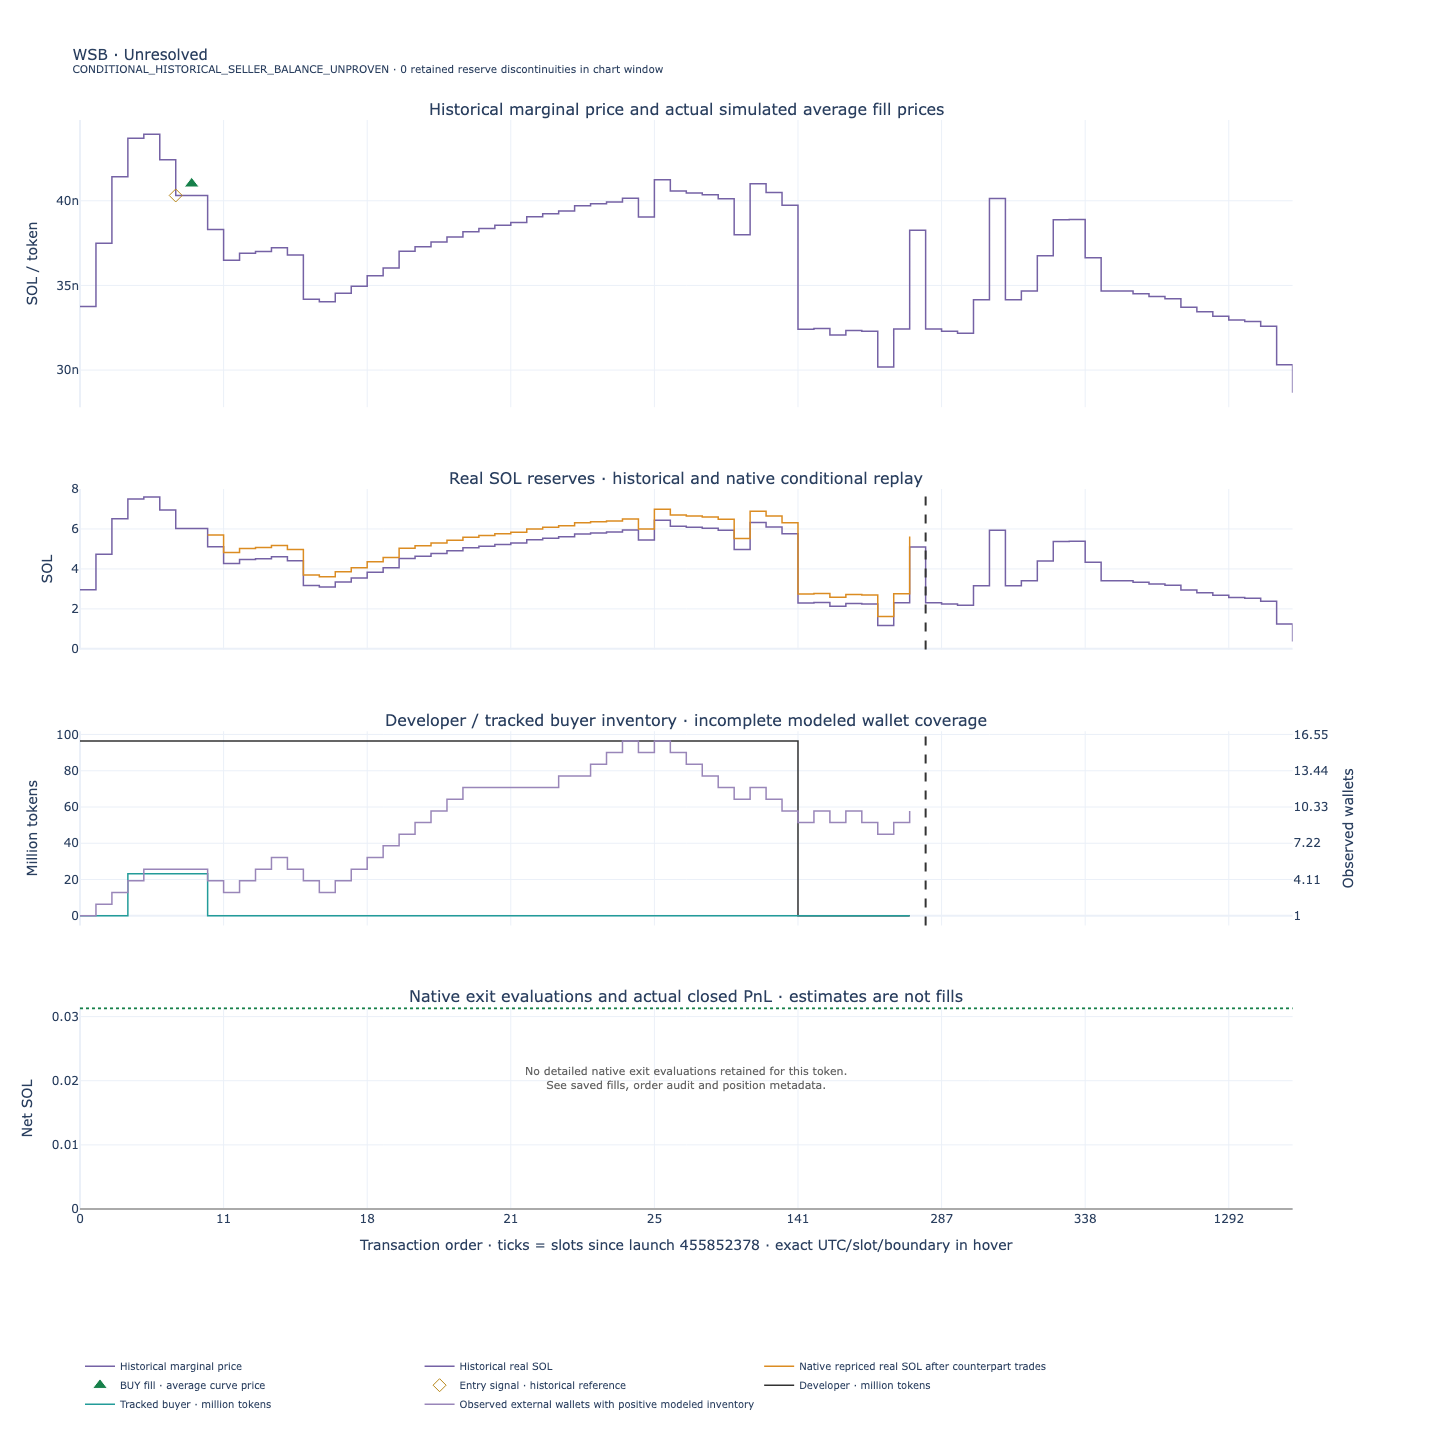

**Complete order audit for this token**

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason
0,1957871059608797194,1957871063903764480,fdc2dfd9023d4b9c7869b0a129ef857f7974e5f6a58f9e6dfabbce18e5007f96,50,ORDER_ACCEPTED_AND_RESERVED,,
1,1957871063903764480,,fdc2dfd9023d4b9c7869b0a129ef857f7974e5f6a58f9e6dfabbce18e5007f96,60,ORDER_FILLED_ATOMICALLY,1,


Detailed step logs were not retained for this token. The signal record, fills and order audit above are original saved evidence.

,Recorded native metadata
status,OPEN
reason,CONDITIONAL_TRANSFER_SOURCE_INVENTORY_CONFLICT
signal_slot,455962740
signal_time,1791789754
entry_slot,455962741
entry_time,1791789755
exit_signal_slot,None
exit_slot,None
exit_time,None
budget_lamports,2675987803


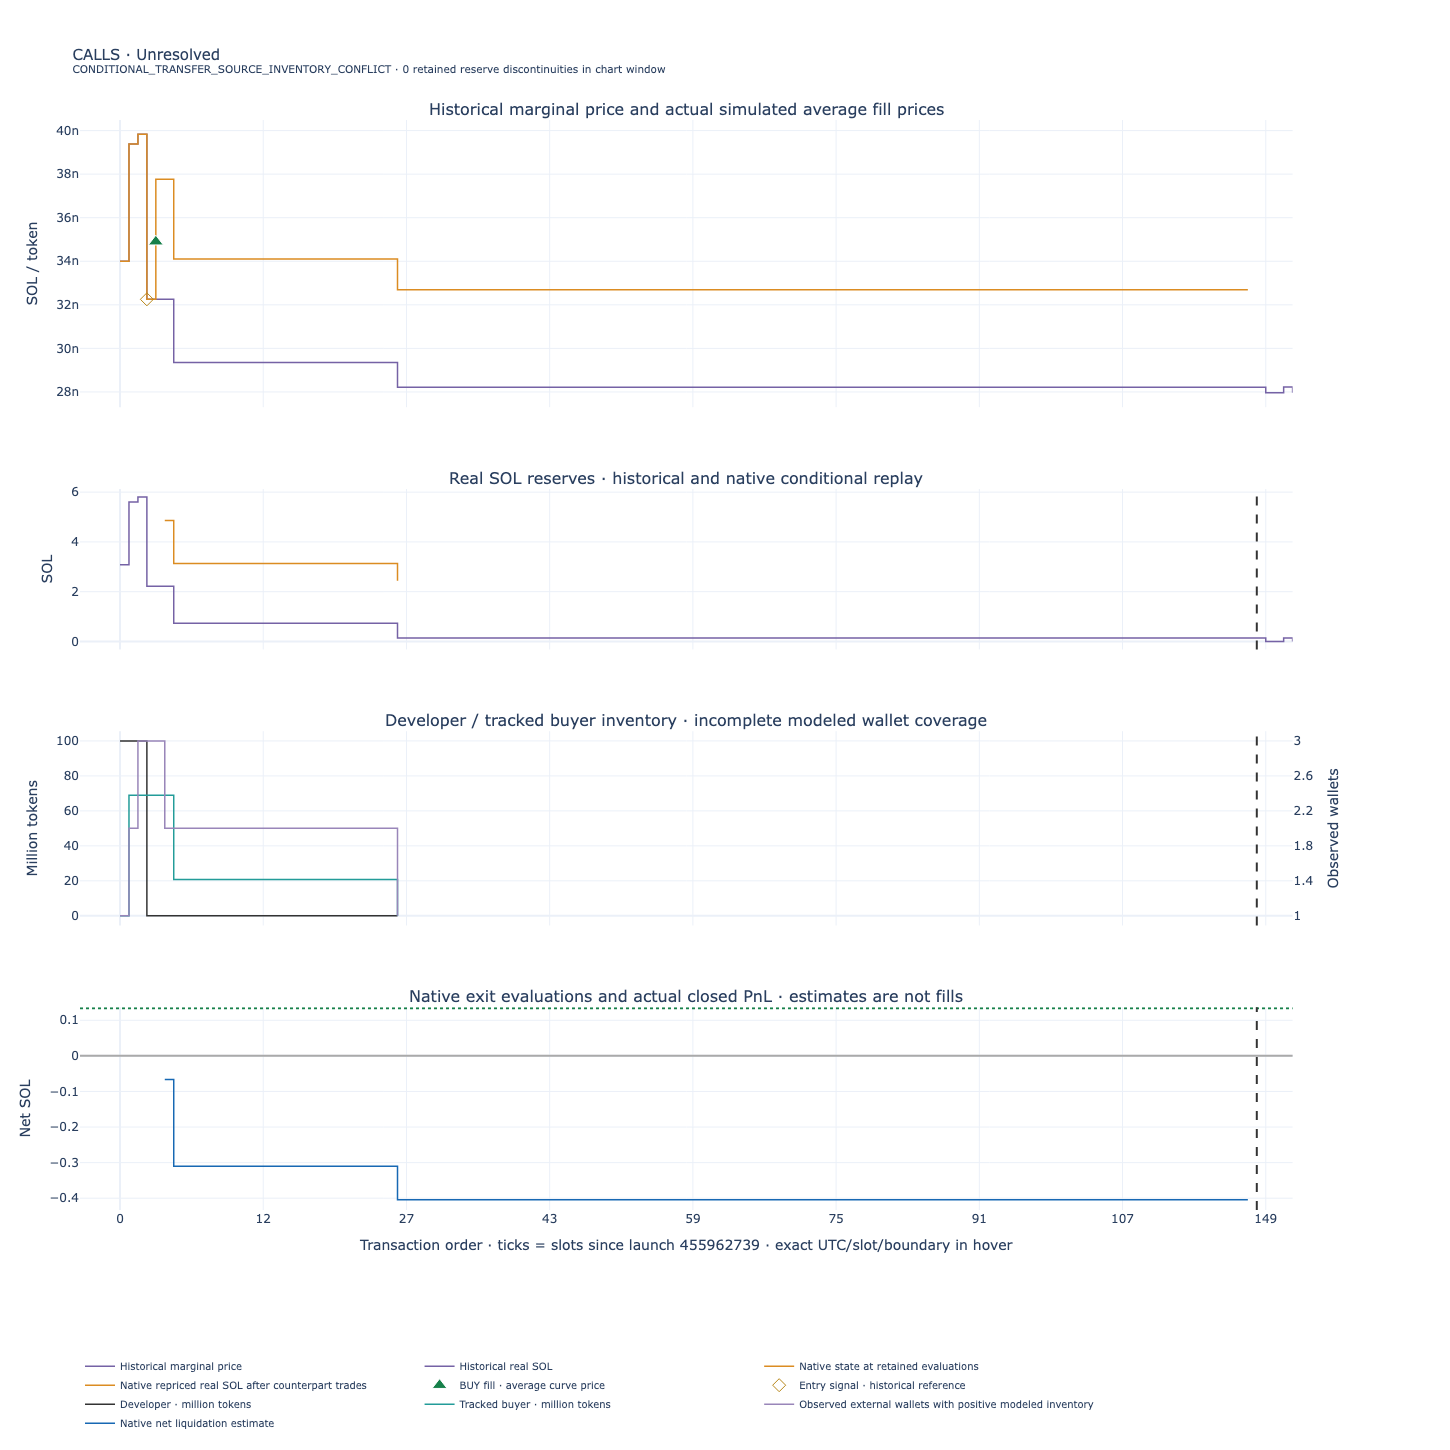

**Complete order audit for this token**

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason
0,1958345056494551160,1958345060789518336,39105feebb2a229b6810c701f0622547b9ef0f25a2ad5168f0077284505a7055,50,ORDER_ACCEPTED_AND_RESERVED,,
1,1958345060789518336,,39105feebb2a229b6810c701f0622547b9ef0f25a2ad5168f0077284505a7055,60,ORDER_FILLED_ATOMICALLY,1,


**Retained detailed evaluations: first and last rows; full log stays in native/strategy_trace.csv**

,mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,wallet,budget_lamports,real_sol,virtual_sol,virtual_tokens,wallet_tokens,...,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
0,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345056494551160,455962740,1791789754,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,2675987803,,32221692412,999016426297671,68986320218760,...,1000000,34864643328,4864643328,75731489727838,2642950916,71944915241446,,,,,,,,,
1,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345056494551160,455962740,1791789754,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,,32221692412,999016426297671,68986320218760,...,,,,,,,BUY,39105feebb2a229b6810c701f0622547b9ef0f25a2ad5168f0077284505a7055,[],0,,,,,
2,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345060789518336,455962741,1791789755,ORDER_FILLED,PENDING_BUY,SIGNAL,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,,34864643328,923284936569833,68986320218760,...,,,,,,,BUY,39105feebb2a229b6810c701f0622547b9ef0f25a2ad5168f0077284505a7055,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
3,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345060789518369,455962741,1791789755,EXIT_EVALUATION,OPEN,HOLDING,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,4864265717,34864265717,923294936569833,68986320218760,...,,,,,,,,,,,-66338168,133804641,False,2642895834,0
4,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345060789518585,455962741,1791789755,EXIT_EVALUATION,OPEN,HOLDING,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,3131417275,33131417275,971585360722965,20695896065628,...,,,,,,,,,,,-310411423,133804641,False,2395733044,0
5,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345065084485632,455962742,1791789755,EXIT_EVALUATION,OPEN,HOLDING,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,3131417275,33131417275,971585360722965,20695896065628,...,,,,,,,,,,,-310411423,133804641,False,2395733044,0
6,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345069379452928,455962743,1791789755,EXIT_EVALUATION,OPEN,HOLDING,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,3131417275,33131417275,971585360722965,20695896065628,...,,,,,,,,,,,-310411423,133804641,False,2395733044,0
7,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345073674420224,455962744,1791789755,EXIT_EVALUATION,OPEN,HOLDING,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,3131417275,33131417275,971585360722965,20695896065628,...,,,,,,,,,,,-310411423,133804641,False,2395733044,0
8,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345077969387520,455962745,1791789756,EXIT_EVALUATION,OPEN,HOLDING,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,3131417275,33131417275,971585360722965,20695896065628,...,,,,,,,,,,,-310411423,133804641,False,2395733044,0
9,H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump,CALLS,1958345082264354816,455962746,1791789756,EXIT_EVALUATION,OPEN,HOLDING,2,EQ5WSWiean8KrS5Z1mpsoyRwViESb9RVA6F1AdtP4Y8D,,3131417275,33131417275,971585360722965,20695896065628,...,,,,,,,,,,,-310411423,133804641,False,2395733044,0


,Recorded native metadata
status,ENTRY_FAILED
reason,RESERVE_DISCONTINUITY
signal_slot,455841299
signal_time,1791763257
entry_slot,None
entry_time,None
exit_signal_slot,None
exit_slot,None
exit_time,None
budget_lamports,18923237930


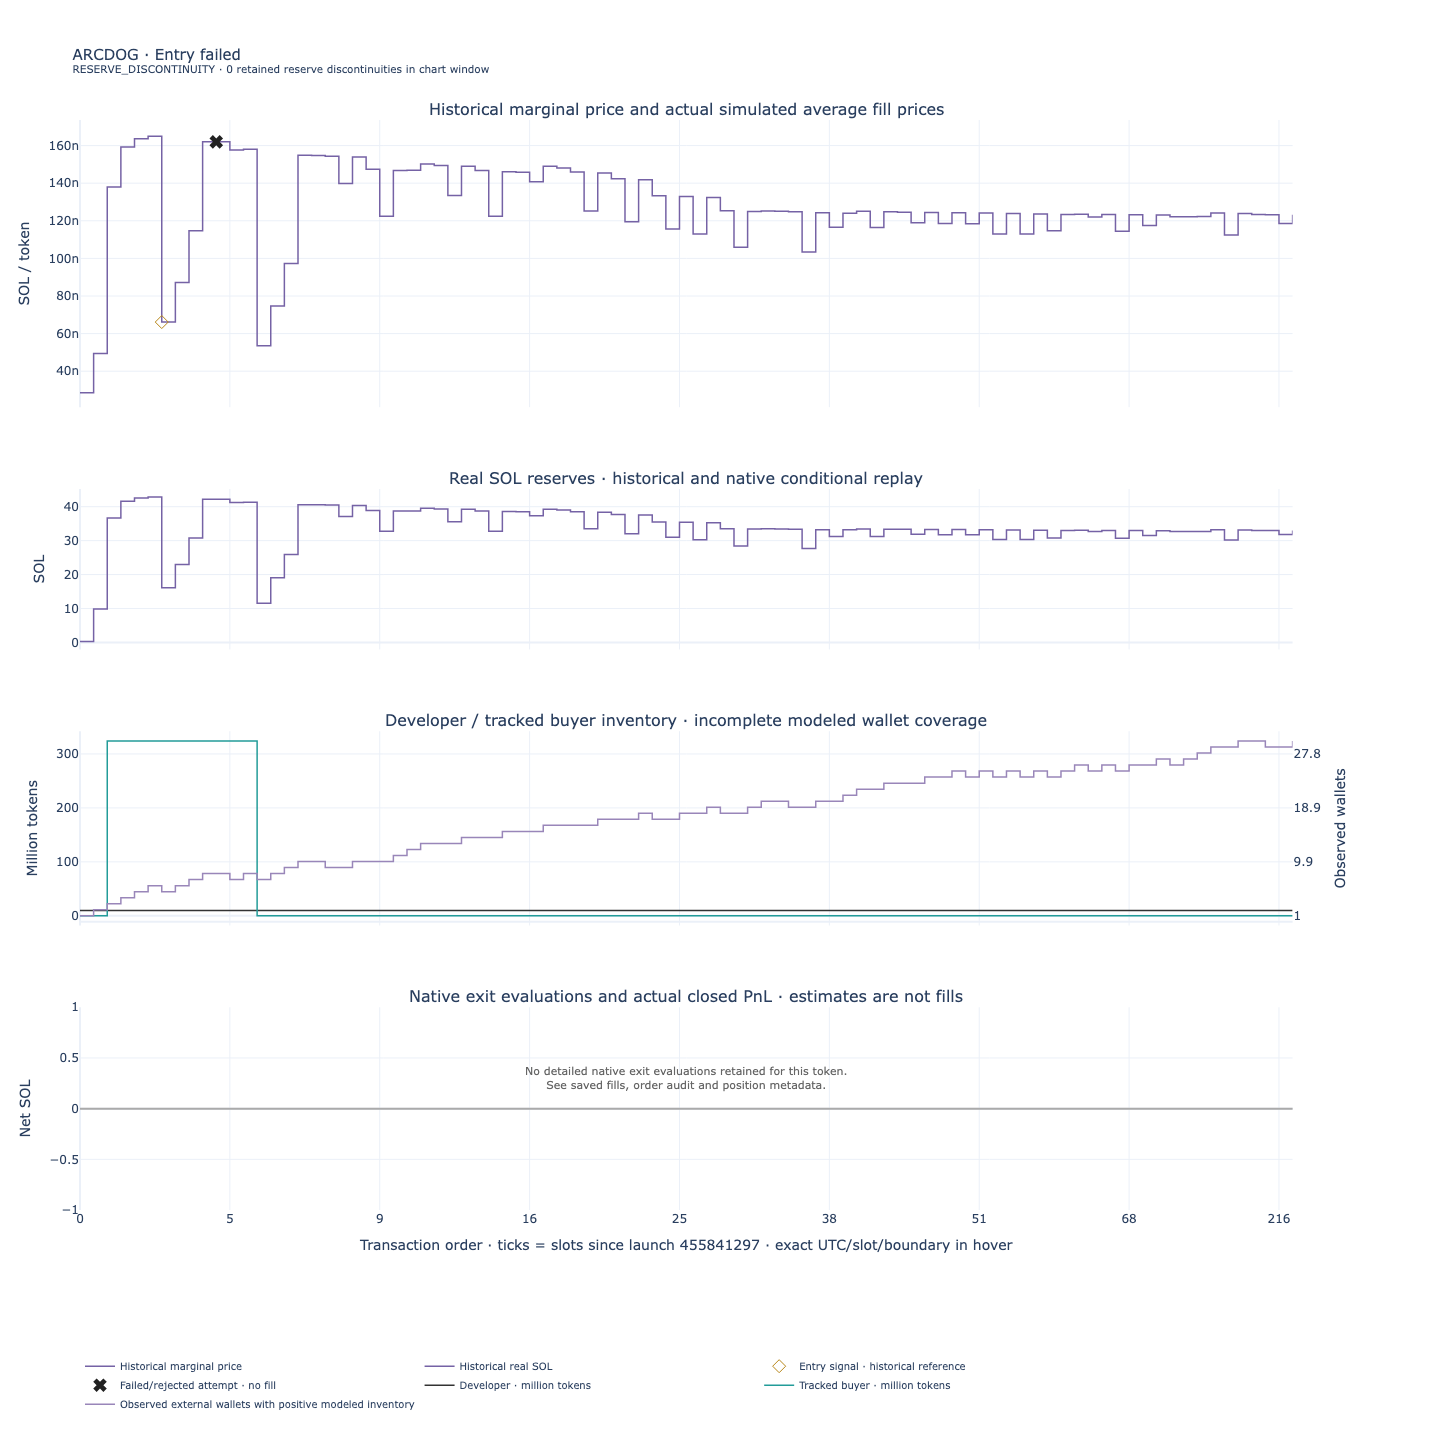

**Complete order audit for this token**

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason
0,1957823471371157759,1957823475666124800,bd4833146e135151fd0e4f94e5c268310b0691a8102febeca1850eeaaa46c0db,50,ORDER_ACCEPTED_AND_RESERVED,,
1,1957823475666124800,,bd4833146e135151fd0e4f94e5c268310b0691a8102febeca1850eeaaa46c0db,60,ORDER_EXECUTION_FAILED_AND_RELEASED,,MINIMUM_OUTPUT_NOT_MET


Detailed step logs were not retained for this token. The signal record, fills and order audit above are original saved evidence.

,Recorded native metadata
status,CLOSED
reason,TARGET
signal_slot,455873873
signal_time,1791770357
entry_slot,455873874
entry_time,1791770358
exit_signal_slot,455873878
exit_slot,455873879
exit_time,1791770359
budget_lamports,1869750256


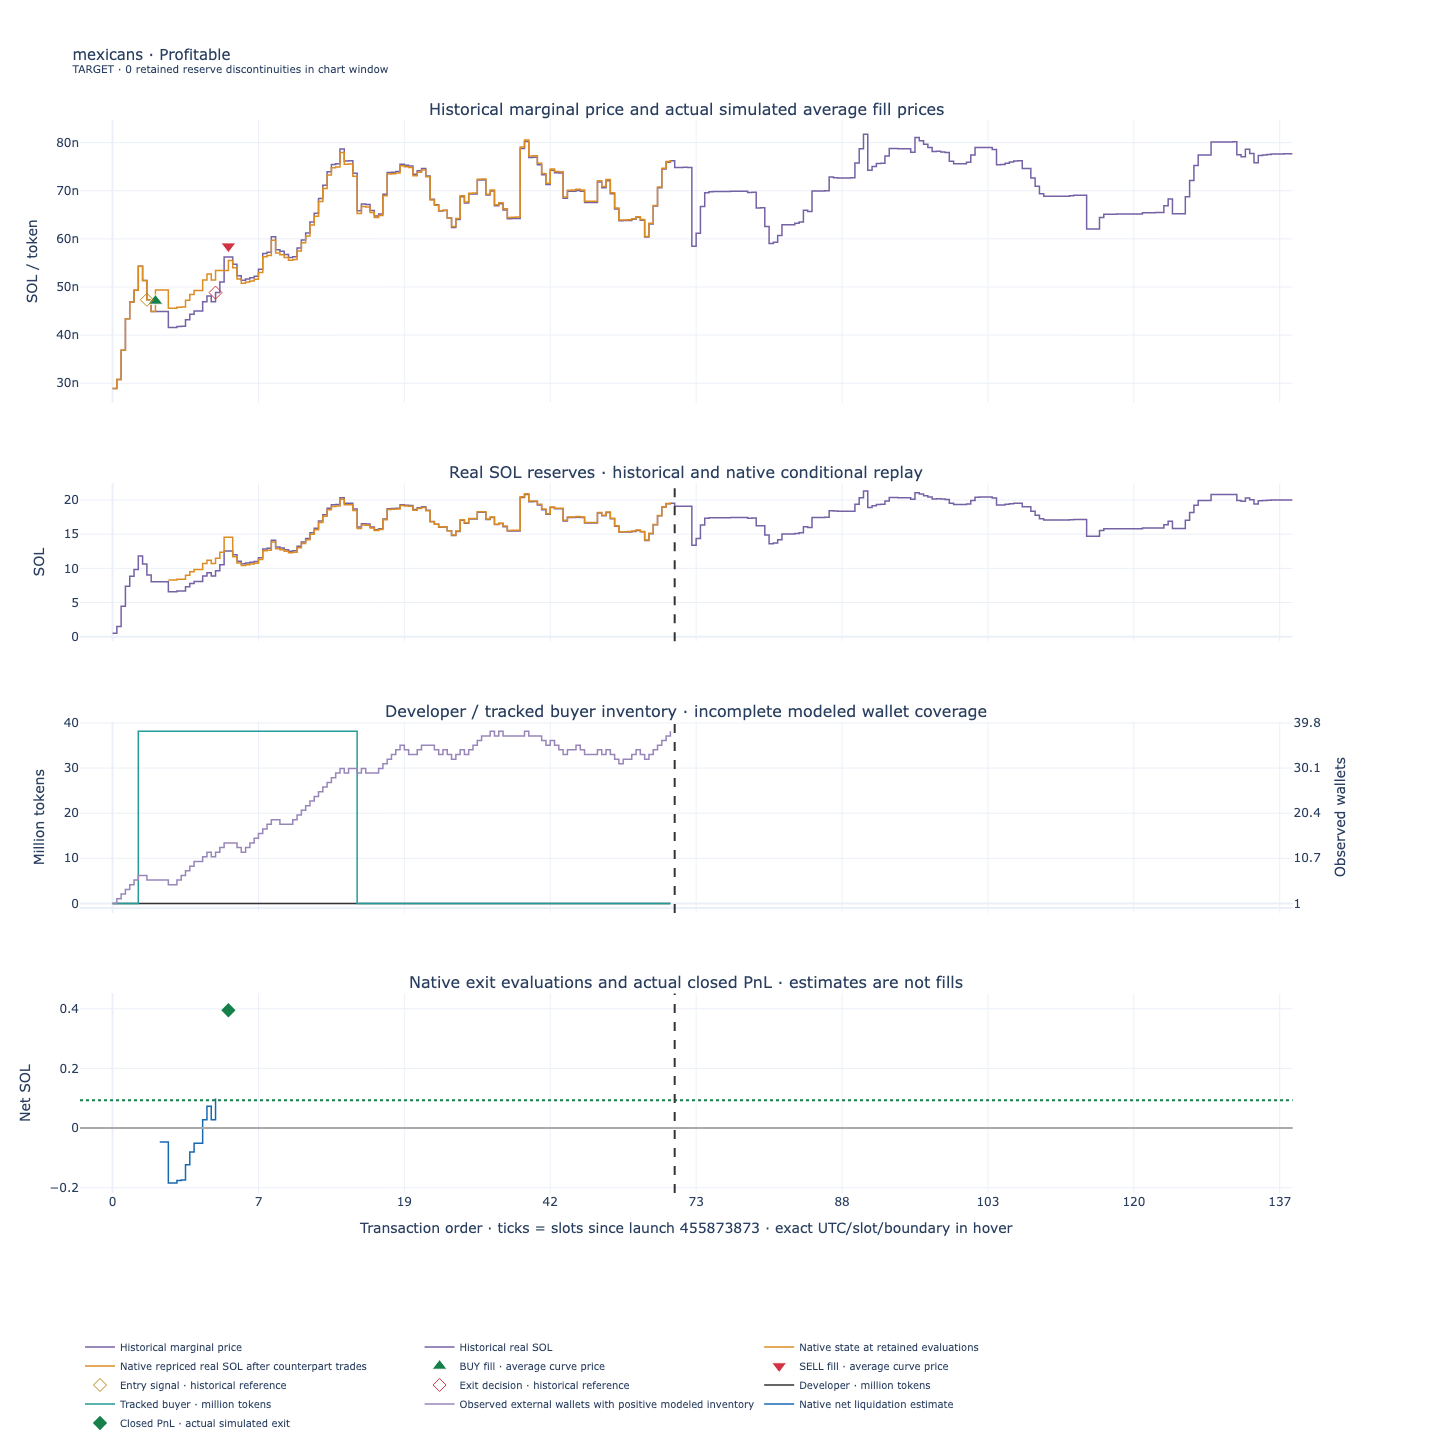

**Complete order audit for this token**

,boundary_ordinal,eligible_boundary_ordinal,order_id,phase,record_type,fill_count,reason
0,1957963375635858195,1957963379930824704,6c3dae79649e168f2b06f09f72c6c20b59b4b2c18dc334286a572bb309e27c72,50,ORDER_ACCEPTED_AND_RESERVED,,
1,1957963379930824704,,6c3dae79649e168f2b06f09f72c6c20b59b4b2c18dc334286a572bb309e27c72,60,ORDER_FILLED_ATOMICALLY,1,
2,1957963397110694892,1957963401405661184,143f55dd4d7ff0046ac4d31c112cb6ad64a1ac534981d9ae9e98b8a4755245d6,50,ORDER_ACCEPTED_AND_RESERVED,,
3,1957963401405661184,,143f55dd4d7ff0046ac4d31c112cb6ad64a1ac534981d9ae9e98b8a4755245d6,60,ORDER_FILLED_ATOMICALLY,1,


**Retained detailed evaluations: first and last rows; full log stays in native/strategy_trace.csv**

,mint,symbol,boundary_ordinal,slot,time,action,status,reason,eligible_wallets,wallet,budget_lamports,real_sol,virtual_sol,virtual_tokens,wallet_tokens,...,epsilon,after_virtual_sol,after_real_sol,quoted_tokens,quoted_curve_deposit,min_tokens,side,order_id,reports,execution_fee,pnl_lamports,target_lamports,timeout,gross_curve_sell,synthetic_shortfall
0,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963375635858195,455873873,1791770357,ENTRY_SIGNAL,PENDING_BUY,SIGNAL,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,1869750256,,39034804210,824648686180597,38168235442724,...,1000000,40881471129,10881471129,37250407231525,1846666919,35387886869948,,,,,,,,,
1,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963375635858195,455873873,1791770357,ORDER_ACCEPTED,PENDING_BUY,SIGNAL,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,,39034804210,824648686180597,38168235442724,...,,,,,,,BUY,6c3dae79649e168f2b06f09f72c6c20b59b4b2c18dc334286a572bb309e27c72,[],0,,,,,
2,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963379930824704,455873874,1791770358,ORDER_FILLED,PENDING_BUY,SIGNAL,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,,39869207388,807390016442205,38168235442724,...,,,,,,,BUY,6c3dae79649e168f2b06f09f72c6c20b59b4b2c18dc334286a572bb309e27c72,"[""UPSTREAM_PUMP_QUOTE"", ""CONDITIONAL_PROTOCOL_REPLAY"", ""real-reserve-capped-v1""]",105000,,,,,
3,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963384225792000,455873875,1791770358,EXIT_EVALUATION,OPEN,HOLDING,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,9869207388,39869207388,807390016442205,38168235442724,...,,,,,,,,,,,-46376675,93492763,False,1846666918,0
4,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963388520759296,455873876,1791770358,EXIT_EVALUATION,OPEN,HOLDING,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,9869207388,39869207388,807390016442205,38168235442724,...,,,,,,,,,,,-46376675,93492763,False,1846666918,0
5,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963388520759904,455873876,1791770358,EXIT_EVALUATION,OPEN,HOLDING,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,8298284755,38298284755,840507615810361,38168235442724,...,,,,,,,,,,,-184174273,93492763,False,1707125047,0
6,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963392815726592,455873877,1791770358,EXIT_EVALUATION,OPEN,HOLDING,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,8298284755,38298284755,840507615810361,38168235442724,...,,,,,,,,,,,-184174273,93492763,False,1707125047,0
7,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963392815727022,455873877,1791770358,EXIT_EVALUATION,OPEN,HOLDING,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,8398737824,38398737824,838308804748468,38168235442724,...,,,,,,,,,,,-175517441,93492763,False,1715891459,0
8,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963392815727139,455873877,1791770358,EXIT_EVALUATION,OPEN,HOLDING,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,8418490909,38418490909,837877783543659,38168235442724,...,,,,,,,,,,,-173812672,93492763,False,1717617808,0
9,71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump,mexicans,1957963392815727159,455873877,1791770358,EXIT_EVALUATION,OPEN,HOLDING,6,3yrJE1A8dgSuy5NLimG5GSYxA6wMkvnAYLD9Y4xR2fjJ,,9005157575,39005157575,825275476681635,38168235442724,...,,,,,,,,,,,-122808168,93492763,False,1769267938,0


In [5]:
EXAMPLES = ['Hb6VWCTaXyCnpheuqCFjTgJUG2qSnF5pQxafJg31pump', '8JYcQbzedkDTAfC7huUi6Pc6L61YC4zzgPcZL4jcpump', 'DjWRDKNHZy9x8KwHYzCHAeQXrEVW8j71JpiHhKcNpump', 'H6ZaULaPVaPEjn55PpkzDrbm9L75X7NJzNHj8c9hpump', '7bHUu6Lxcy75vuR6EgNuepjwpUUBthDbwVqAode2pump', '71tjJyUstGVqDN4VPQaLLaawPxqYiJb8e9uFU9R4pump']
for mint in EXAMPLES:
    review.show(mint)

## Inspect another token

Set `TOKEN` to a mint from any outcome table, then rerun the next cell.

In [6]:
TOKEN = EXAMPLES[0]
# review.show(TOKEN)  # Uncomment after choosing a token.

## Unresolved cases and log coverage

**75 positions** lack enough retained historical seller acquisitions or transfers
to prove inventory at the next sell. **5 positions** have a fixed-transfer
conflict: our simulated intervention leaves the sender with fewer tokens than
the historical transfer requires. Neither proves that our own sell was submitted
and failed. One final lifecycle label was overwritten by migration; the first
causal blocker is preserved in the table.

Detailed per-event strategy evaluations exist for **78 tokens**. All **887 signals**
have native signal metadata and a complete order audit, and all **649 buys and
569 sells** have exact native fill/ledger records. Missing detailed evaluations
are explicitly labeled rather than reconstructed as if they were recorded logs.

Developer and tracked-buyer balances use retained swaps, native repriced amounts,
and the bounded verified transfer overlay. Wallet counts are incomplete modeled
coverage, not exact holders. These series stop at the first conditional blocker.
Historical chart lines are retained observations, not a complete chain audit.

In [7]:
display(review.table[review.table.group == 'Unresolved'].groupby('first_causal_blocker').agg(
    positions=('mint', 'count'), committed_cost_sol=('open_committed_cost_sol', 'sum')))
display(review.table.groupby(['group', 'detailed_native_log']).size().rename('tokens').to_frame())

,positions,committed_cost_sol
first_causal_blocker,,
CONDITIONAL_HISTORICAL_SELLER_BALANCE_UNPROVEN,75,141.771907
CONDITIONAL_TRANSFER_SOURCE_INVENTORY_CONFLICT,5,10.547244


tokens
group        detailed_native_log        
Entry failed False                   238
Losing       False                   264
             True                     54
Profitable   False                   232
             True                     19
Unresolved   False                    75
             True                      5

## Parameters and provenance

The notebook binds the immutable native result, all order/fill records, and the
bounded historical context with file hashes. It uses the repaired input version
from the completed experiment; no additional history was silently added for the
new positions. Network fees, fee tiers and within-slot landing remain the saved
simulation assumptions.

In [8]:
display(pd.Series(review.summary['policy'], name='Saved policy').to_frame())
display(pd.Series({
    'source_input_sha256': review.summary['source_input_sha256'],
    'native_manifest_sha256': review.receipt['native_manifest_sha256'],
    'engine_source_sha256': review.summary['implementation']['engine_source_sha256'],
    'full_chain_coverage': review.summary['full_chain_coverage'],
    'exact_execution': review.summary['exact_execution'],
    'chart_facts': review.receipt['chart_facts'],
    'chart_tokens': review.receipt['positions'],
}, name='Retained provenance').to_frame())

,Saved policy
early_slots,2
minimum_sniper_buy_lamports,1000000000
target_return_bps,500
epsilon_lamports,1000000
entry_delay_slots,1
exit_delay_slots,1
holding_seconds,300
entry_network_fee_lamports,105000
exit_network_fee_lamports,105000
entry_tip_lamports,0


,Retained provenance
source_input_sha256,dd62a8ac8fb2f3981b50af94e8b9af378b760e9dd62735f7dd490092e188bdd3
native_manifest_sha256,48d7033f3ee640da71f449d7ed84d05452c5eab123bd2686ccbf0f64863a059c
engine_source_sha256,f93a8de0259cfd5de2fea152df072ad80a09aa72adb5bedbfebbcc2766df62f0
full_chain_coverage,False
exact_execution,False
chart_facts,93324
chart_tokens,887


## CSV exports

The local data folder contains all positions split by outcome, native fill
markers, realized PnL events, cash events and committed-cost events. The `native`
folder preserves the complete order audit, retained detailed logs, conditional
errors, fills and ledger. There is no separate HTML report.

In [9]:
print(review.export)
display(pd.DataFrame({"CSV file": sorted(p.name for p in review.export.glob("*.csv"))}))

./var/dnipro/sniper-oct12-no-dev-flat-review-20261016-v1/csv


,CSV file
0,all_positions.csv
1,breakeven.csv
2,cash_events.csv
3,committed_cost_events.csv
4,entry_failed.csv
5,entry_rejected.csv
6,exposure_events.csv
7,fill_markers.csv
8,losing.csv
9,native_fill_markers.csv
